In [1]:
# zebrafish L = 3 的结果不是想要的。 在L = 6 的时候10 2 6，20 2 6 也不是想要的。

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from scipy.sparse import csr_matrix
import scvelo as scv
from torch.optim import SGD, Adam, Adagrad
from function import *

from utils import *
from g2g_model_Fisher import *
import itertools

In [3]:
data_path = "/home/linux/桌面/SCIM-main/main/data/branch_data/"
path_path = "/home/linux/桌面/Is single cell sloppy?/4_FI_vs_Velocity/RC_path/"
cmap = plt.colormaps['Spectral_r']
save = False

[k_nei, K, L] = [10, 3, 3]
computing neighbors
    finished (0:00:01) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 3386 × 600
    obs: 'split_id', 'sample', 'Size_Factor', 'condition', 'Cluster', 'celltype', 'umap_1', 'umap_2', 'batch', 'n_counts', 'Cell_type', 'voronoi_id_Schwann Cell', 'voronoi_id_Xanthophore', 'voronoi_id_Melanophore'
    var: 'n_cells', 'gene_count_corr', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'Cell_type_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'umap', 'velocity_params'
    obsm: 'X_eigengene', 'X_hotspot', 'X_

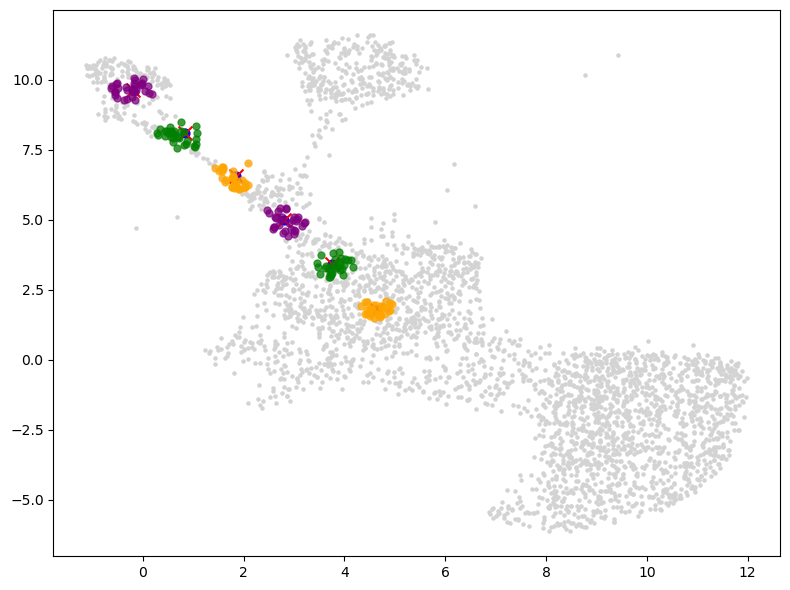

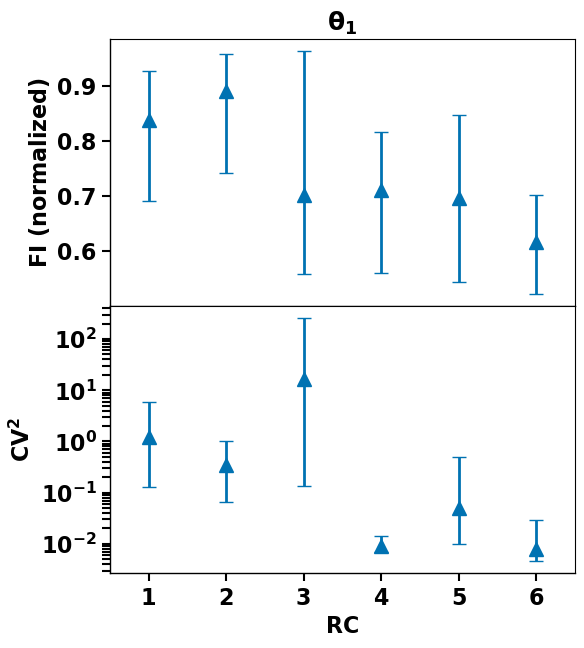

y: [1.2431166e+00 3.4360552e-01 1.6792595e+01 9.2288135e-03 5.0241746e-02
 7.9138493e-03]
max_vals: [5.9467878e+00 1.0442166e+00 2.5344804e+02 1.4538497e-02 4.9378148e-01
 2.9369276e-02]
min_vals: [0.13080634 0.06613884 0.13434751 0.00678972 0.00980077 0.00460729]
error: [[1.1123103e+00 2.7746668e-01 1.6658247e+01 2.4390980e-03 4.0440977e-02
  3.3065630e-03]
 [4.7036715e+00 7.0061111e-01 2.3665546e+02 5.3096833e-03 4.4353974e-01
  2.1455426e-02]]
y: [ 0.5065409   0.14794907  0.5598099   2.0791714   0.39033255 73.62731   ]
max_vals: [2.7300062e+00 4.9562684e-01 1.7040128e+00 3.6441734e+01 1.7065985e+00
 2.0514873e+03]
min_vals: [0.00950216 0.0568672  0.21169282 0.1049186  0.03613179 0.0088512 ]
error: [[4.9703875e-01 9.1081865e-02 3.4811711e-01 1.9742528e+00 3.5420075e-01
  7.3618462e+01]
 [2.2234654e+00 3.4767777e-01 1.1442028e+00 3.4362564e+01 1.3162659e+00
  1.9778600e+03]]
y: [1305.4972      11.17316    376.36508      7.976476     7.318093
    3.4732215]
max_vals: [3.6647750e+04 5.4

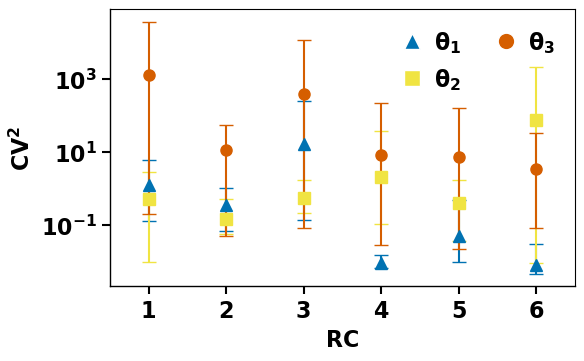

pca_svd_rc_mean_all:
[[[ 2.540196    3.585399    0.283823  ]
  [ 2.533579    3.9889205   0.76303077]
  [ 1.7973003   3.0444384   3.502808  ]
  [ 0.58873767  2.102676    0.02106743]
  [ 1.6007826   2.6014907   3.9470804 ]
  [ 1.5848062   2.0460875   3.0686345 ]
  [ 2.254233    2.8212433   0.24332812]
  [ 1.6387727   1.9588583   2.8623354 ]
  [ 1.1223954   2.6972537   1.7286918 ]
  [ 2.5687282   3.654828    1.1907705 ]
  [ 2.365355    3.24426    -0.27444795]
  [ 2.0859056   3.151325    3.3606737 ]
  [ 2.3398297   3.4801629   2.751302  ]
  [ 1.6212697   3.363197    3.430198  ]
  [ 2.093175    4.424012    1.236057  ]
  [ 1.7909023   2.1631813   3.3383243 ]
  [ 0.88845766  2.0430572  -0.07199863]
  [ 2.2158494   3.977548    1.3034979 ]
  [ 3.0094397   3.5981982   0.3395954 ]
  [ 1.2055898   3.640323    0.36971864]
  [ 1.5087934   2.8390877   3.788456  ]
  [ 2.109861    1.5147446   2.5736122 ]
  [ 1.9306504   2.0933042   2.1161969 ]
  [ 1.71704     2.1395488   3.1713417 ]
  [ 2.2299871   2.7

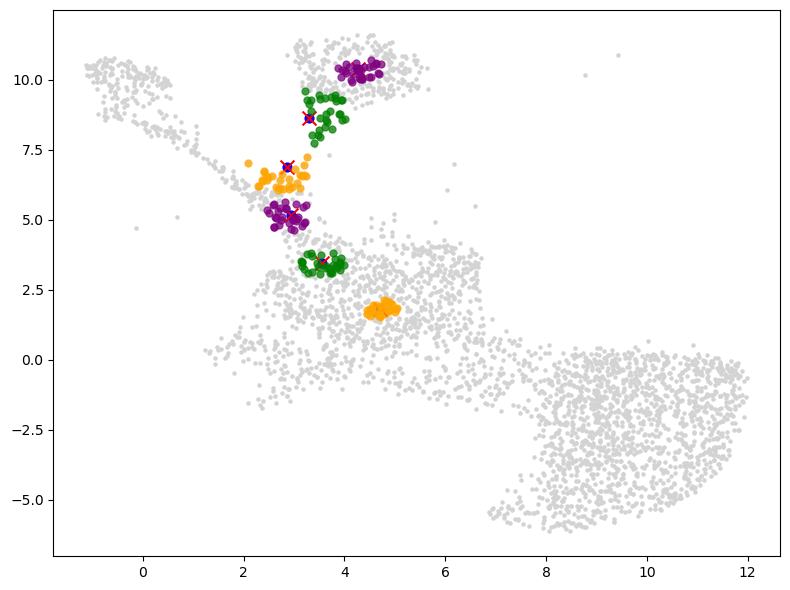

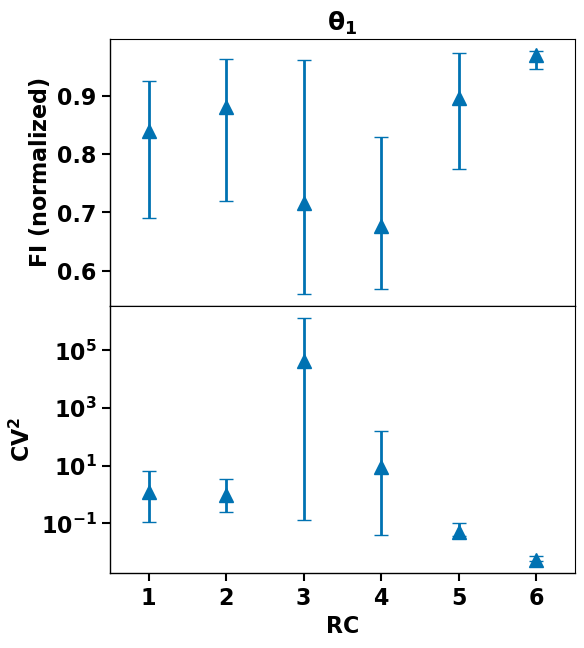

y: [1.1933048e+00 9.3991679e-01 4.2540605e+04 9.0955629e+00 4.9654048e-02
 5.5109691e-03]
max_vals: [6.7074828e+00 3.4916360e+00 1.2757406e+06 1.6167065e+02 1.0455346e-01
 7.5507089e-03]
min_vals: [0.11146957 0.2589585  0.13119894 0.03862958 0.03768763 0.00494276]
error: [[1.08183527e+00 6.80958271e-01 4.25404727e+04 9.05693340e+00
  1.19664185e-02 5.68212941e-04]
 [5.51417828e+00 2.55171919e+00 1.23320000e+06 1.52575089e+02
  5.48994131e-02 2.03973986e-03]]
y: [0.6629186  0.2311872  0.5710087  0.4190587  0.28482193 0.15428123]
max_vals: [3.9305809 1.1275674 1.8776599 2.6673925 0.514783  2.1057878]
min_vals: [0.00919792 0.09267795 0.2244495  0.0564984  0.1970532  0.04773818]
error: [[0.65372074 0.13850924 0.34655917 0.3625603  0.08776873 0.10654305]
 [3.2676623  0.8963802  1.3066512  2.2483337  0.2299611  1.9515065 ]]
y: [386.51144    25.611376   10.578513    1.6263629  27.54376     4.1327853]
max_vals: [5958.652    259.22623  200.66777   37.44527  423.54626   91.90906]
min_vals: [0.04

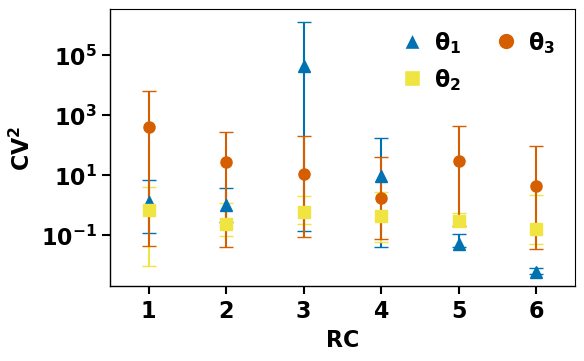

pca_svd_rc_mean_all:
[[[ 1.59898651e+00  2.57782602e+00  4.04062223e+00]
  [ 2.56166077e+00  3.61364388e+00  2.81370759e-01]
  [ 1.63506055e+00  1.94498384e+00  2.90879703e+00]
  [ 1.10832763e+00  2.69825125e+00  1.70652449e+00]
  [ 1.79871535e+00  3.03397083e+00  3.61079884e+00]
  [ 1.61926830e+00  3.36041760e+00  3.52793527e+00]
  [ 2.56671762e+00  4.02595997e+00  7.86182106e-01]
  [ 2.60443616e+00  3.68979120e+00  1.23312020e+00]
  [ 5.51007092e-01  2.10074258e+00 -5.18594496e-02]
  [ 1.57813179e+00  2.00541496e+00  3.14437461e+00]
  [ 1.19711339e+00  3.66816163e+00  2.57184148e-01]
  [ 3.03965092e+00  3.64714885e+00  3.28380048e-01]
  [ 1.79218423e+00  2.14667034e+00  3.40779233e+00]
  [ 2.09380317e+00  3.15406752e+00  3.46369505e+00]
  [ 2.37962723e+00  3.26556301e+00 -2.89230019e-01]
  [ 2.26987147e+00  2.82846594e+00  2.42999390e-01]
  [ 2.34804416e+00  3.52821755e+00  2.82691979e+00]
  [ 8.81765306e-01  2.05543613e+00 -7.40592927e-02]
  [ 2.10278845e+00  4.46641302e+00  1.29982

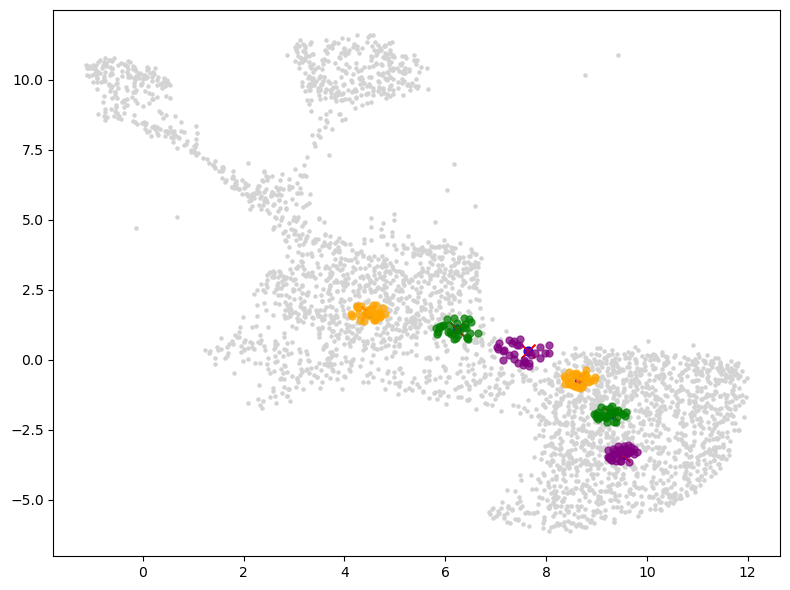

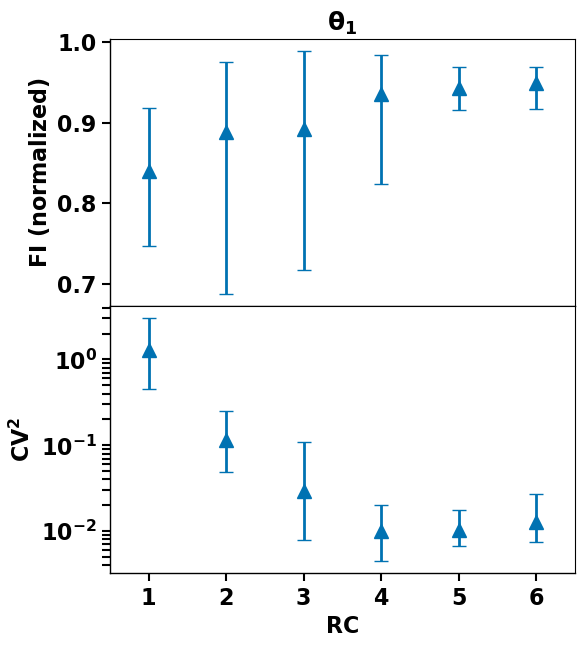

y: [1.2902904  0.11410271 0.02907968 0.01013134 0.01035606 0.01266312]
max_vals: [3.0047255  0.2475934  0.10826057 0.0203321  0.01768248 0.02705471]
min_vals: [0.44671163 0.04906016 0.00785017 0.00447678 0.00664413 0.00745815]
error: [[0.8435787  0.06504256 0.02122951 0.00565456 0.00371194 0.00520497]
 [1.7144351  0.13349068 0.0791809  0.01020076 0.00732642 0.0143916 ]]
y: [0.39859316 0.15687132 8.274058   0.295942   0.08272009 0.09276617]
max_vals: [ 1.6705626   0.37484735 91.322815    1.2350941   0.1396514   0.17900355]
min_vals: [0.00661595 0.05269892 0.22695453 0.08449814 0.04170596 0.0465082 ]
error: [[3.9197719e-01 1.0417239e-01 8.0471039e+00 2.1144387e-01 4.1014127e-02
  4.6257969e-02]
 [1.2719694e+00 2.1797603e-01 8.3048759e+01 9.3915206e-01 5.6931317e-02
  8.6237378e-02]]
y: [9.3836411e+01 9.3196698e+02 1.1585664e+03 6.0910048e+00 1.1845114e+06
 1.0490382e+00]
max_vals: [1.4859952e+03 2.6321443e+04 3.2714680e+04 1.0849223e+02 3.5535336e+07
 1.2646423e+01]
min_vals: [0.45482764

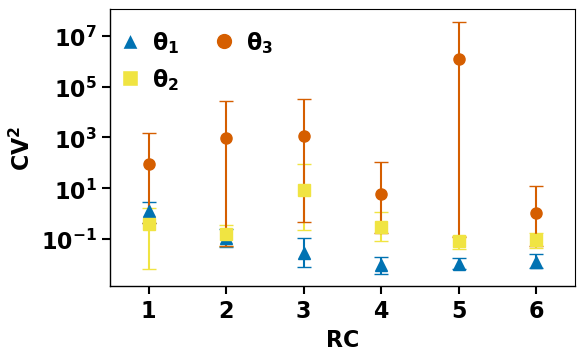

pca_svd_rc_mean_all:
[[[ 1.83419824e+00  3.50139260e+00  1.11741972e+00]
  [ 1.65806746e+00  2.23315024e+00  1.85539293e+00]
  [ 1.46356428e+00  2.42360973e+00  2.17933607e+00]
  [ 1.78079641e+00  3.86204672e+00  6.33265436e-01]
  [ 7.00926363e-01  2.12689447e+00  7.22333014e-01]
  [ 1.36029840e+00  2.73288369e+00  2.84418130e+00]
  [ 1.88485932e+00  2.74098110e+00  2.98588753e-01]
  [ 1.99050963e+00  3.52928376e+00  5.60274661e-01]
  [ 1.69457686e+00  2.82763219e+00  2.33110666e+00]
  [ 1.59190118e+00  3.06734681e+00  2.29457545e+00]
  [ 2.10984945e+00  3.24333477e+00  3.44804317e-01]
  [ 2.06394267e+00  3.00047946e+00  1.85495245e+00]
  [ 1.54052877e+00  2.33306193e+00  2.32654190e+00]
  [ 1.81491303e+00  3.05858755e+00  2.20653296e+00]
  [ 1.64384258e+00  3.06552887e+00  1.09375246e-01]
  [ 7.93971717e-01  1.91989648e+00  1.58853576e-01]
  [ 1.83881438e+00  2.79426861e+00  4.27205890e-01]
  [ 1.28684306e+00 -3.05513501e+00  6.23429537e-01]
  [ 1.72471261e+00  2.50385499e+00  2.22751

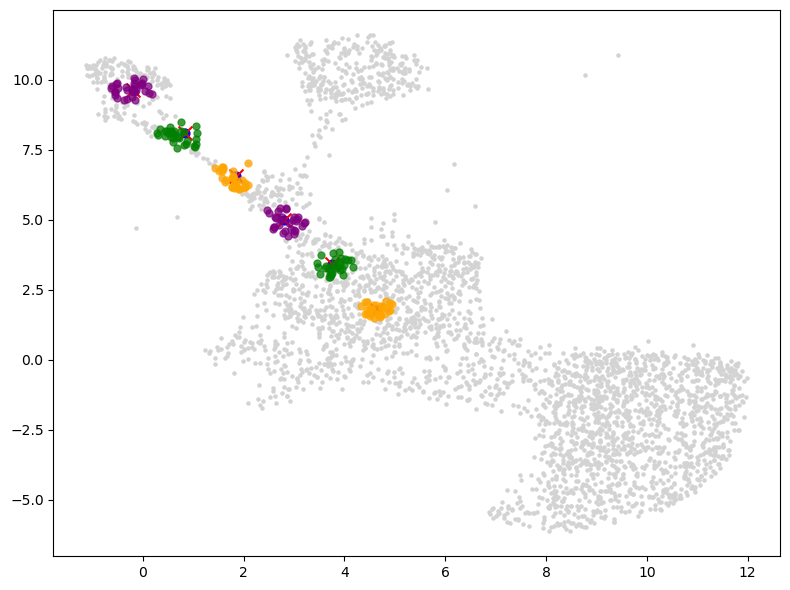

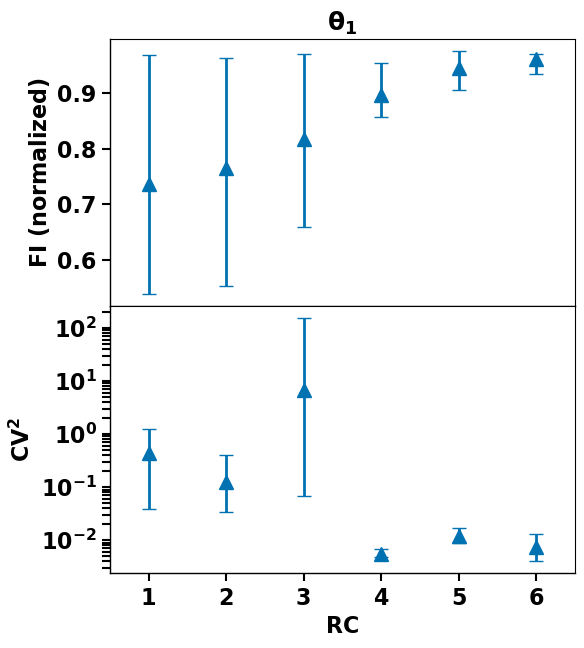

y: [4.4028094e-01 1.2675694e-01 6.8794637e+00 5.3908941e-03 1.1993847e-02
 7.5548762e-03]
max_vals: [1.2427037e+00 4.0029755e-01 1.5039755e+02 6.6928272e-03 1.7041903e-02
 1.3163327e-02]
min_vals: [0.03823991 0.03425683 0.06650922 0.00483312 0.00879095 0.00403349]
error: [[4.0204105e-01 9.2500106e-02 6.8129544e+00 5.5777421e-04 3.2028919e-03
  3.5213828e-03]
 [8.0242276e-01 2.7354062e-01 1.4351808e+02 1.3019331e-03 5.0480561e-03
  5.6084511e-03]]
y: [3.2369933e-01 9.8726191e-02 2.6540978e+00 1.5386316e+03 9.2004770e-01
 8.6305074e-02]
max_vals: [1.4151459e+00 2.8104401e-01 7.2024288e+00 4.3284402e+04 2.1606184e+01
 1.5823513e-01]
min_vals: [0.04417764 0.03749743 0.04868301 0.03682873 0.02916036 0.0629505 ]
error: [[2.7952170e-01 6.1228763e-02 2.6054149e+00 1.5385947e+03 8.9088732e-01
  2.3354575e-02]
 [1.0914465e+00 1.8231782e-01 4.5483313e+00 4.1745770e+04 2.0686136e+01
  7.1930058e-02]]
y: [6.3384961e+02 3.1780484e+02 3.1812778e+00 1.1652531e-01 1.0818835e+00
 4.3261699e-02]
max_vals

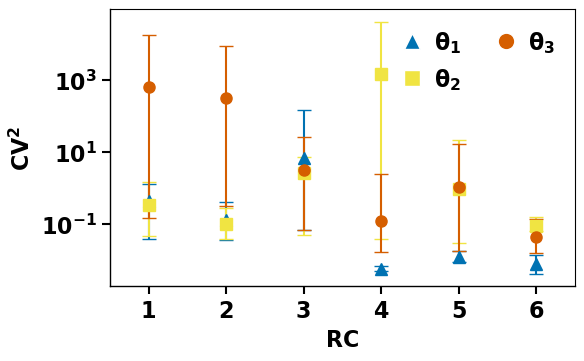

pca_svd_rc_mean_all:
[[[ 3.25702834e+00 -3.06652927e+00  2.52903843e+00]
  [ 2.75427699e+00 -3.62704253e+00  2.60682702e+00]
  [ 2.51458263e+00  2.80168247e+00 -1.24832916e+00]
  [-1.62663019e+00  2.45264339e+00  2.08752435e-02]
  [ 2.42022777e+00 -2.89750409e+00  1.03294444e+00]
  [ 2.34667873e+00  1.79695654e+00 -7.08345473e-01]
  [ 2.59430814e+00 -2.77057052e+00  1.19011009e+00]
  [ 2.65296221e+00  2.27052546e+00 -9.21673954e-01]
  [ 2.73610854e+00 -1.79449236e+00 -1.67274415e+00]
  [ 2.51170444e+00 -3.78045249e+00  2.42303514e+00]
  [ 2.02712941e+00 -3.02283382e+00  1.86377656e+00]
  [ 2.70559025e+00  2.80216479e+00 -1.51685894e+00]
  [ 2.66028357e+00  2.74578309e+00 -7.50619590e-01]
  [ 2.50226498e+00 -2.99655652e+00  1.28936434e+00]
  [ 2.35376072e+00 -3.79332757e+00  2.50780964e+00]
  [ 1.84524417e+00 -2.54862189e+00  9.92343545e-01]
  [ 2.77063036e+00 -7.08681941e-01 -2.02209330e+00]
  [ 3.26198959e+00 -3.27943516e+00  2.32258177e+00]
  [ 3.25997138e+00 -3.07117820e+00  2.25731

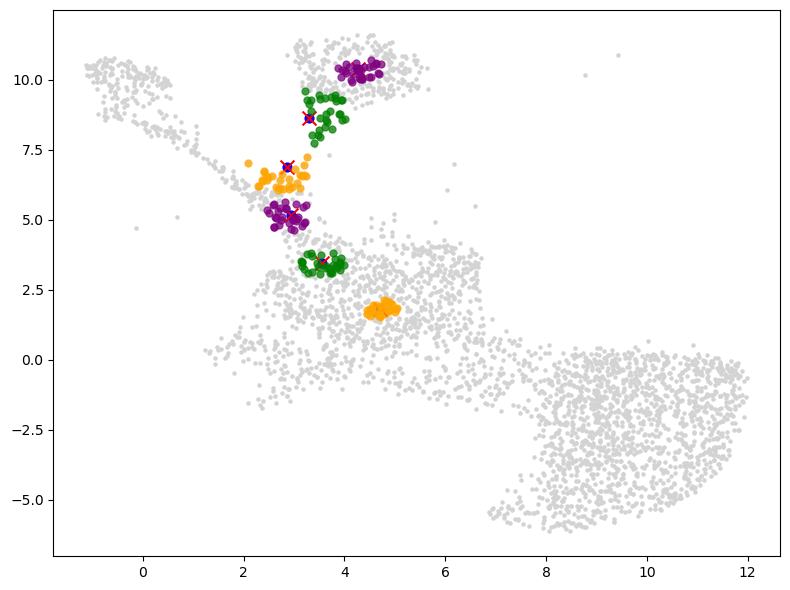

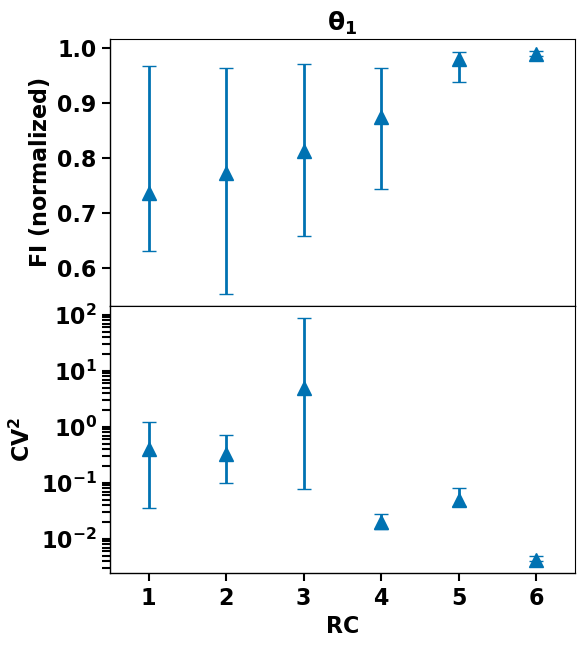

y: [4.0423021e-01 3.2794508e-01 4.8580308e+00 1.9987883e-02 4.8999894e-02
 4.1620177e-03]
max_vals: [1.2236238e+00 7.2475708e-01 8.6587265e+01 2.8133783e-02 7.9928771e-02
 4.9387007e-03]
min_vals: [0.03626746 0.09876042 0.07762083 0.01506668 0.03887062 0.00401097]
error: [[3.6796275e-01 2.2918466e-01 4.7804098e+00 4.9212072e-03 1.0129273e-02
  1.5104469e-04]
 [8.1939352e-01 3.9681199e-01 8.1729233e+01 8.1459004e-03 3.0928876e-02
  7.7668298e-04]]
y: [ 0.32783434  0.14436303  2.8043396  25.043427   20.650557    0.68819463]
max_vals: [  1.4235376   0.7477313   8.245588  601.449     557.46204     5.270561 ]
min_vals: [0.04328926 0.05996072 0.04639581 0.33654714 0.24942018 0.08249411]
error: [[2.8454506e-01 8.4402308e-02 2.7579439e+00 2.4706879e+01 2.0401136e+01
  6.0570049e-01]
 [1.0957032e+00 6.0336828e-01 5.4412489e+00 5.7640552e+02 5.3681146e+02
  4.5823665e+00]]
y: [2.3276726e+02 1.1548496e+03 3.2590804e+00 1.3502962e+01 2.8819257e-01
 5.1616143e-02]
max_vals: [5.9459365e+03 2.8415248

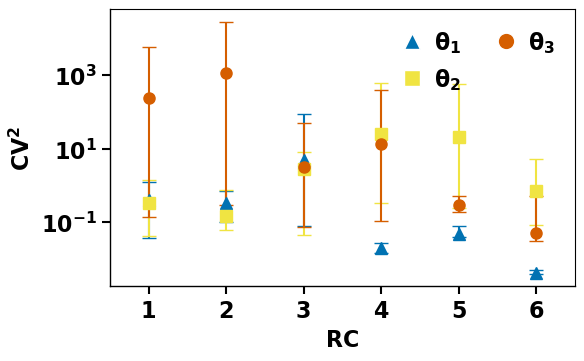

pca_svd_rc_mean_all:
[[[ 2.40497470e+00 -2.90518069e+00  1.09562635e+00]
  [ 3.27891088e+00 -3.08546472e+00  2.65105319e+00]
  [ 2.64045811e+00  2.27332401e+00 -9.75840151e-01]
  [ 2.71390128e+00 -1.79222441e+00 -1.67061341e+00]
  [ 2.49975514e+00  2.81020999e+00 -1.31764746e+00]
  [ 2.49303794e+00 -3.00656295e+00  1.36318207e+00]
  [ 2.77337027e+00 -3.65451860e+00  2.72540903e+00]
  [ 2.52708435e+00 -3.81243443e+00  2.53299117e+00]
  [-1.63914537e+00  2.46416831e+00 -3.66872326e-02]
  [ 2.31888604e+00  1.78147364e+00 -7.64046669e-01]
  [ 1.85695636e+00  4.30808258e+00 -4.90565270e-01]
  [ 3.27017927e+00 -3.08812714e+00  2.33377576e+00]
  [ 1.82304776e+00 -2.54382849e+00  1.01792943e+00]
  [ 2.69714284e+00  2.81288552e+00 -1.59774101e+00]
  [ 2.03495955e+00 -3.02767944e+00  1.94698536e+00]
  [ 2.60574031e+00 -2.77764273e+00  1.26835418e+00]
  [ 2.65248466e+00  2.75885844e+00 -7.87421525e-01]
  [ 2.75890350e+00 -7.07368970e-01 -2.00873637e+00]
  [ 2.35769773e+00 -3.81446886e+00  2.58507

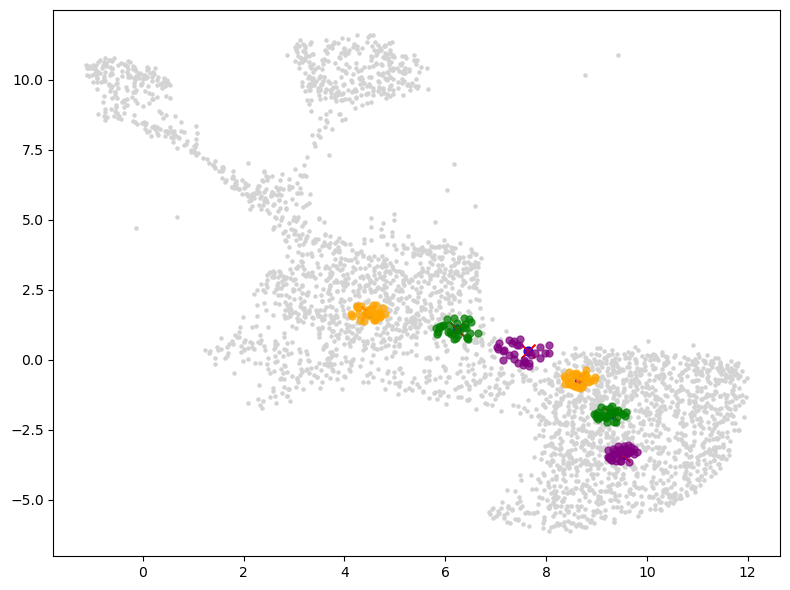

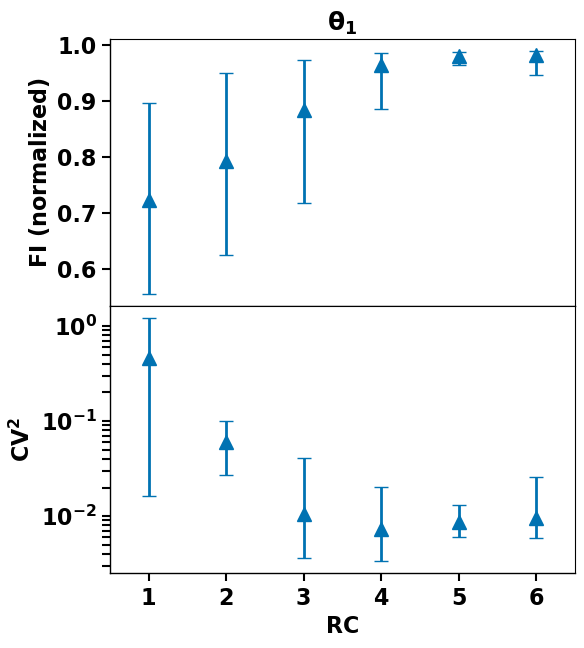

y: [0.46197784 0.06007307 0.01048624 0.00734595 0.00867504 0.00960297]
max_vals: [1.2039946  0.10093127 0.04053264 0.02036442 0.01309456 0.02571742]
min_vals: [0.01626722 0.02734949 0.00363682 0.00336078 0.00606849 0.00586276]
error: [[0.44571063 0.03272358 0.00684942 0.00398517 0.00260655 0.0037402 ]
 [0.7420168  0.04085821 0.0300464  0.01301848 0.00441952 0.01611445]]
y: [ 0.3289712   0.151826   75.4401      0.10095618  0.09675564  0.08682372]
max_vals: [2.2861931e+00 1.1858557e+00 1.9803011e+03 1.4525358e-01 1.2185716e-01
 1.1487516e-01]
min_vals: [0.01868148 0.05403342 1.2304333  0.05624079 0.05268113 0.03605108]
error: [[3.1028974e-01 9.7792573e-02 7.4209671e+01 4.4715390e-02 4.4074506e-02
  5.0772637e-02]
 [1.9572220e+00 1.0340297e+00 1.9048611e+03 4.4297405e-02 2.5101520e-02
  2.8051443e-02]]
y: [1.0868477e+02 1.2169382e+01 4.4282887e+01 8.8749453e+04 2.7499311e+01
 5.2001734e+00]
max_vals: [2.2657981e+03 1.5322267e+02 7.1164752e+02 2.6594192e+06 3.2082367e+02
 8.1351593e+01]
mi

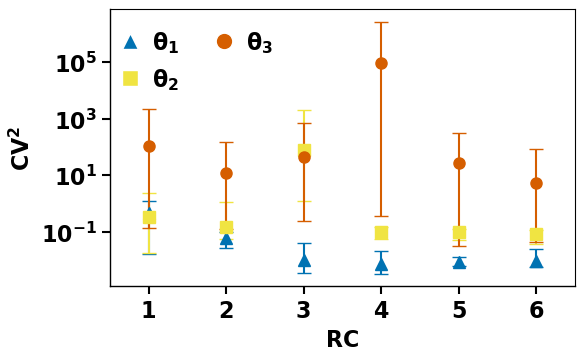

pca_svd_rc_mean_all:
[[[ 2.77285409e+00 -3.00360799e+00  1.27103341e+00]
  [ 2.33921862e+00  2.50212550e+00 -6.41769767e-01]
  [ 2.42771769e+00  1.97308850e+00 -2.73346156e-01]
  [ 2.06626582e+00 -3.45683956e+00  1.69511306e+00]
  [-1.62495816e+00  2.21334505e+00  4.82117444e-01]
  [ 2.39811921e+00  2.76153398e+00 -4.52740729e-01]
  [ 2.26371050e+00 -2.69594073e+00  4.92068797e-01]
  [ 2.32300711e+00 -3.28035021e+00  1.42450535e+00]
  [ 2.22967815e+00 -2.92918897e+00  7.37503588e-01]
  [ 2.44656110e+00  2.67927146e+00 -6.52751982e-01]
  [ 2.78698230e+00 -2.84246516e+00  1.34498250e+00]
  [ 2.52765656e+00  2.59342813e+00 -4.66586143e-01]
  [ 1.96162355e+00 -2.38252354e+00  4.63228732e-01]
  [ 2.56913996e+00  2.66043162e+00 -7.98053384e-01]
  [ 1.35217929e+00 -3.24808955e+00  1.51005661e+00]
  [ 2.82297158e+00 -7.60664761e-01 -1.87905836e+00]
  [ 1.61802232e+00 -2.86757374e+00  1.30793250e+00]
  [ 1.40955532e+00 -3.28673601e+00  1.45261335e+00]
  [ 2.74002838e+00 -2.81552148e+00  7.61664

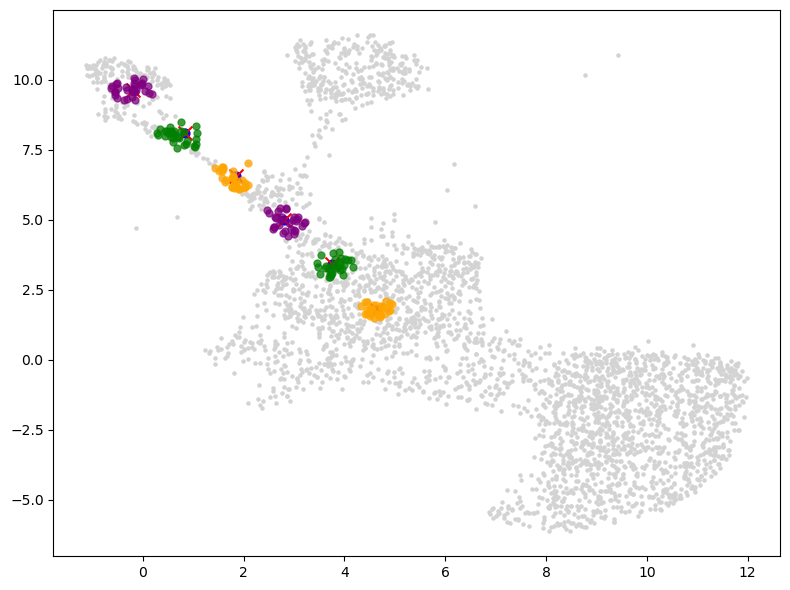

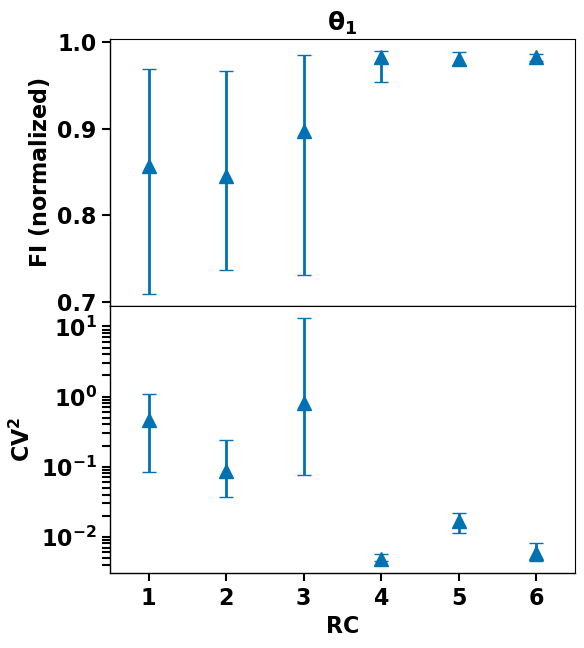

y: [0.45926103 0.08588079 0.8192714  0.00484914 0.01676137 0.00589165]
max_vals: [1.1032310e+00 2.4370055e-01 1.3031700e+01 5.6771082e-03 2.1969857e-02
 8.0496194e-03]
min_vals: [0.08477762 0.03687536 0.07476146 0.00448347 0.01143198 0.00456965]
error: [[3.7448341e-01 4.9005430e-02 7.4450994e-01 3.6567356e-04 5.3293910e-03
  1.3220017e-03]
 [6.4396989e-01 1.5781976e-01 1.2212429e+01 8.2796719e-04 5.2084830e-03
  2.1579703e-03]]
y: [ 0.41753954  0.11999118  5.782536   31.13918     0.2248134   0.09622642]
max_vals: [1.54582381e+00 2.78328687e-01 4.96687851e+01 5.18211609e+02
 1.53593791e+00 1.20647594e-01]
min_vals: [0.02830298 0.06866957 0.06999892 0.15608981 0.11593534 0.05734675]
error: [[3.8923657e-01 5.1321618e-02 5.7125373e+00 3.0983089e+01 1.0887806e-01
  3.8879678e-02]
 [1.1282842e+00 1.5833750e-01 4.3886250e+01 4.8707242e+02 1.3111246e+00
  2.4421170e-02]]
y: [35.518295    1.1636996   1.9479033   0.08955187  0.05447216  0.16182923]
max_vals: [6.4820367e+02 4.2725348e+00 7.655909

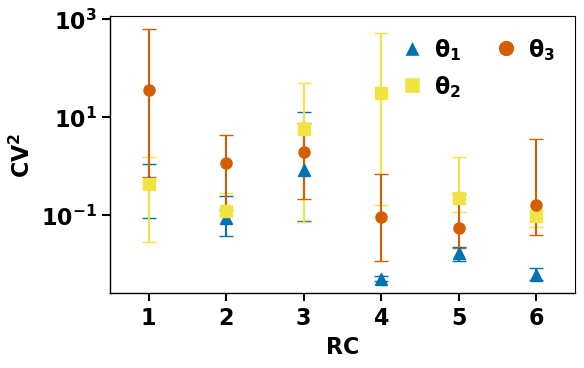

pca_svd_rc_mean_all:
[[[  3.4209275    2.6954503   -1.8007488 ]
  [  3.2534802    3.0016158   -1.692329  ]
  [  3.1350749    2.7700171    0.31413326]
  [ -2.148147     2.600561    -0.82985884]
  [  2.7166564    2.4967844    0.7778155 ]
  [  2.6597602    1.9131845    0.40085644]
  [  2.6446404    2.367173    -2.123337  ]
  [  2.6884625    1.594886     0.44832784]
  [  2.6408544    0.68382204  -2.5915866 ]
  [  3.2245703    1.797091    -1.1879133 ]
  [  2.5613794    2.4339685   -2.2884314 ]
  [  3.004089     2.8719811    0.24855883]
  [  2.6115086    2.9852457    0.7651041 ]
  [  2.9039207    3.059384     0.1977751 ]
  [  3.0695658    3.6708083   -1.1469477 ]
  [  2.4565892    2.3619077    0.9550091 ]
  [  2.5636714    0.7164703   -1.4980512 ]
  [  3.796969     2.8405201   -1.075145  ]
  [  3.219696     2.8847768   -0.9744058 ]
  [  1.9859662    3.772261     0.6062321 ]
  [  2.9435494    3.0479653    0.03363933]
  [  2.7957027    2.9248407    2.6344526 ]
  [  2.8732567    2.4201925    1.

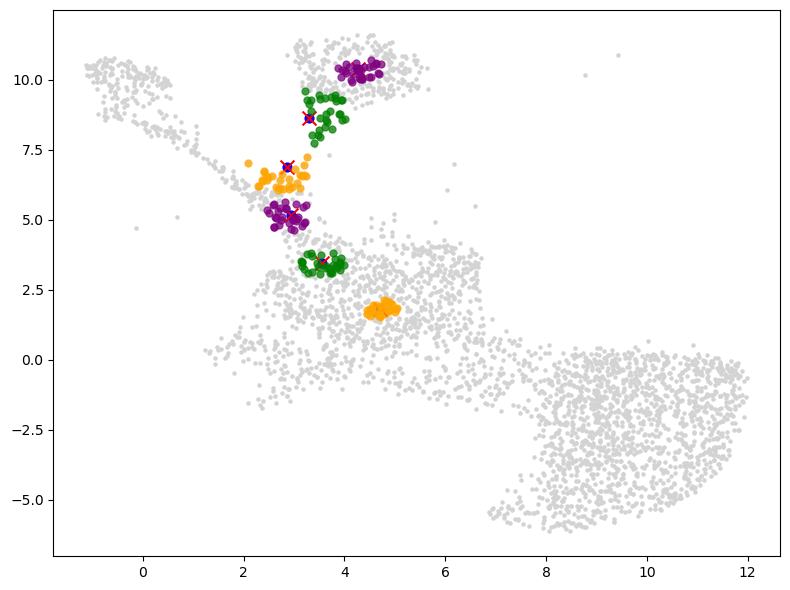

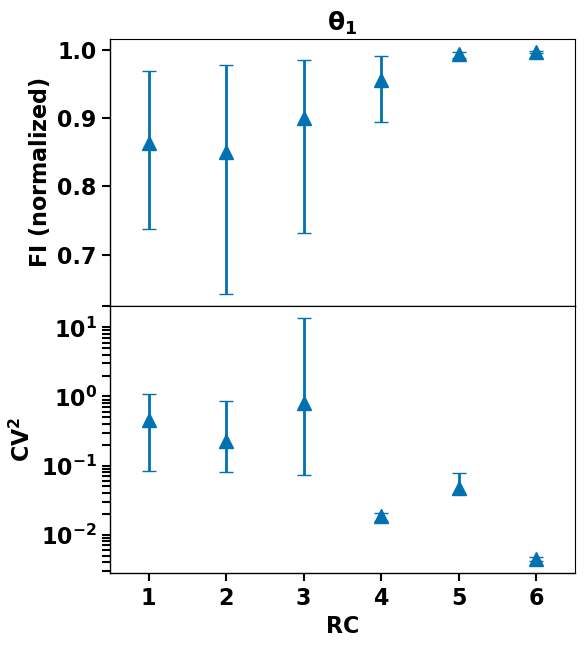

y: [0.45450372 0.22719423 0.80794734 0.01842658 0.04748384 0.0045061 ]
max_vals: [1.0843039e+00 8.5714233e-01 1.3441697e+01 2.0639624e-02 7.7336207e-02
 4.7399821e-03]
min_vals: [0.0825187  0.08168837 0.07434069 0.01584541 0.03869291 0.00416054]
error: [[3.7198502e-01 1.4550588e-01 7.3360664e-01 2.5811717e-03 8.7909214e-03
  3.4556212e-04]
 [6.2980014e-01 6.2994808e-01 1.2633750e+01 2.2130441e-03 2.9852372e-02
  2.3388350e-04]]
y: [ 0.43557024  0.35377944  8.7483635  12.124633    3.4027052   0.06395532]
max_vals: [  1.5394111   3.4330404 117.5725    214.69917    79.74608     0.6266552]
min_vals: [0.02781732 0.08964401 0.07366277 0.307793   0.12756118 0.03328697]
error: [[4.0775293e-01 2.6413542e-01 8.6747007e+00 1.1816840e+01 3.2751441e+00
  3.0668352e-02]
 [1.1038408e+00 3.0792608e+00 1.0882414e+02 2.0257454e+02 7.6343376e+01
  5.6269991e-01]]
y: [39.783306    9.438086    1.9493916   0.70368874  0.78280056  3.2671938 ]
max_vals: [660.6913    150.50224     9.456267    1.8968235   7.857

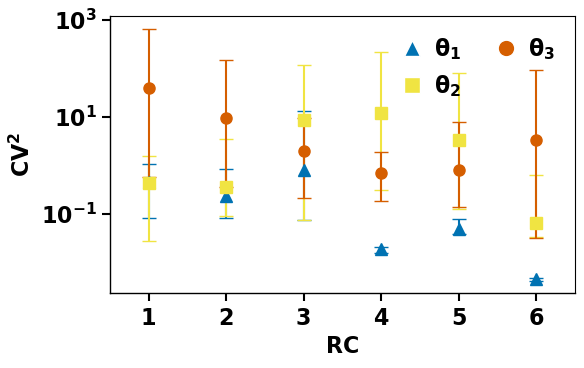

pca_svd_rc_mean_all:
[[[  2.7094803    2.5045526    0.7966754 ]
  [  3.4425952    2.715909    -1.857205  ]
  [  2.6750534    1.5829349    0.45467675]
  [  2.6215632    0.6837747   -2.5743709 ]
  [  3.139137     2.7904997    0.33031803]
  [  2.907161     3.0822258    0.21487886]
  [  3.2758622    3.0263438   -1.7410108 ]
  [  3.2386827    1.8050395   -1.2238921 ]
  [ -2.1563203    2.6210964   -0.8980258 ]
  [  2.6475377    1.9073263    0.41923055]
  [  1.9685643    3.7665217    0.5749331 ]
  [  3.2269127    2.9055777   -0.97322404]
  [  2.4444194    2.3628528    1.0321283 ]
  [  3.0082648    2.8923867    0.26477104]
  [  2.5597389    2.4423983   -2.3387244 ]
  [  2.6444526    2.375243    -2.1641934 ]
  [  2.600917     3.0044744    0.812447  ]
  [  2.5507557    0.71663976  -1.488262  ]
  [  3.0842927    3.7086701   -1.1571133 ]
  [  2.7992947    2.9277637    2.7231462 ]
  [  2.704162     2.408549     0.29154557]
  [  2.2438803    3.2019973    0.5260807 ]
  [  3.8254542    2.8733456   -1.

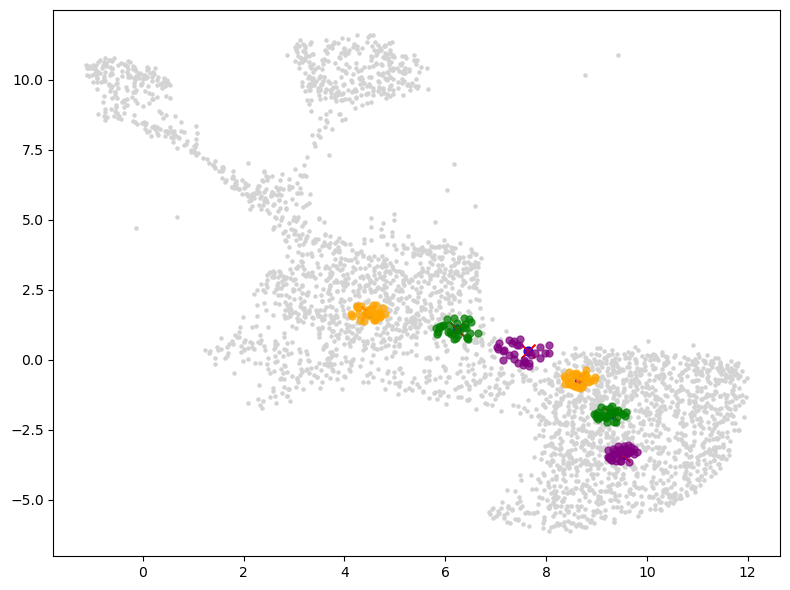

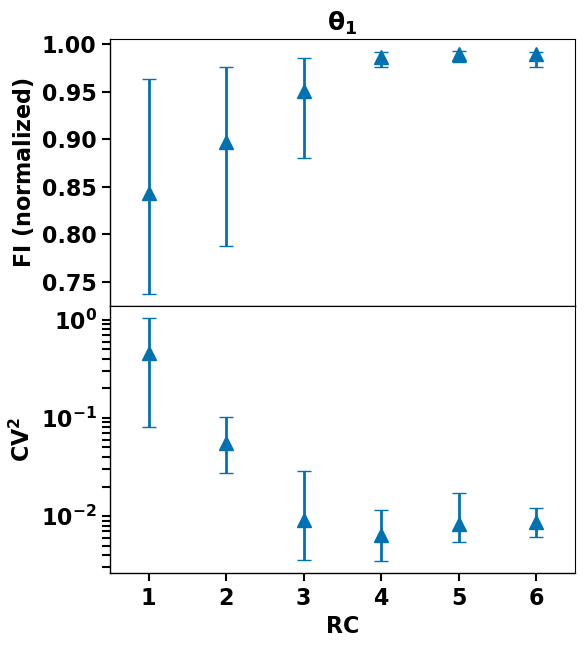

y: [0.46360698 0.05563552 0.0092179  0.00635712 0.0082256  0.00877819]
max_vals: [1.0344428  0.10253239 0.02894827 0.01151985 0.01720941 0.01217679]
min_vals: [0.08021966 0.02756427 0.00353308 0.00347211 0.00539729 0.00615334]
error: [[0.38338733 0.02807124 0.00568482 0.00288501 0.00282831 0.00262485]
 [0.5708358  0.04689687 0.01973037 0.00516273 0.00898381 0.0033986 ]]
y: [0.31902996 0.14359774 4.7360487  0.16777952 0.10656843 0.0878723 ]
max_vals: [ 1.4491905   0.31389484 46.58799     0.3730246   0.13836917  0.11301374]
min_vals: [0.01259994 0.06929237 0.97912896 0.10543662 0.09239463 0.07522353]
error: [[3.0643001e-01 7.4305363e-02 3.7569199e+00 6.2342905e-02 1.4173798e-02
  1.2648769e-02]
 [1.1301606e+00 1.7029710e-01 4.1851940e+01 2.0524509e-01 3.1800747e-02
  2.5141440e-02]]
y: [3.3491550e+02 1.7158405e+03 1.1491804e+03 4.5218494e+01 7.7666527e-01
 8.6074448e+01]
max_vals: [6.8742705e+03 5.0654684e+04 3.2867672e+04 1.0930609e+03 9.8695316e+00
 2.3985044e+03]
min_vals: [0.45685697

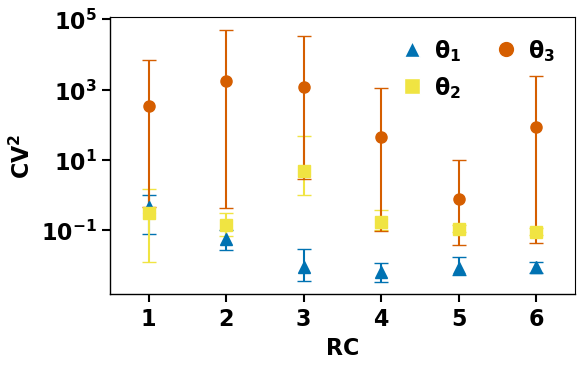

pca_svd_rc_mean_all:
[[[ 3.25722957e+00  2.52439451e+00 -7.20780492e-01]
  [ 2.63698554e+00  2.41728282e+00  6.93471670e-01]
  [ 2.58077407e+00  2.01226068e+00  1.83648959e-01]
  [ 2.65888190e+00  3.23167205e+00 -9.48917687e-01]
  [-2.14335537e+00  2.20735025e+00 -2.05230400e-01]
  [ 2.69277668e+00  2.76553655e+00  2.02913806e-02]
  [ 2.43298769e+00  2.32225561e+00 -1.59742737e+00]
  [ 2.79536891e+00  2.74608159e+00 -1.13229132e+00]
  [ 2.79712248e+00  2.66435266e+00  1.81318447e-01]
  [ 2.85910153e+00  2.56486559e+00  1.31260768e-01]
  [ 2.96850538e+00  2.50207448e+00 -1.17258728e+00]
  [ 2.48248267e+00  2.77624917e+00  2.79503375e-01]
  [ 2.62545156e+00  1.92691600e+00  3.86580348e-01]
  [ 2.73649096e+00  2.65831327e+00  7.33382925e-02]
  [ 2.54150295e+00  2.47680306e+00 -1.62712324e+00]
  [ 2.59889603e+00  8.23165655e-01 -1.31658053e+00]
  [ 2.43410277e+00  2.46598053e+00 -1.89435637e+00]
  [ 2.53623939e+00  2.48306751e+00 -1.78651369e+00]
  [ 2.84954834e+00  2.32400727e+00  1.16566

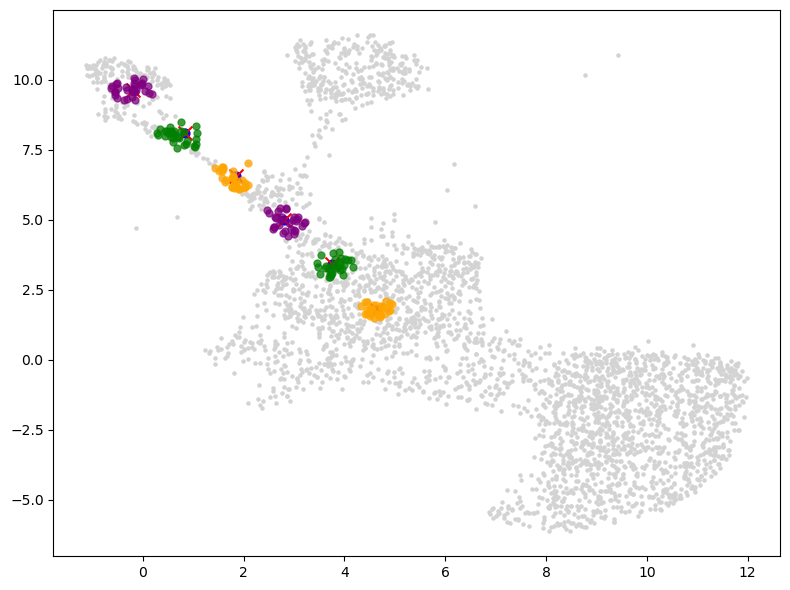

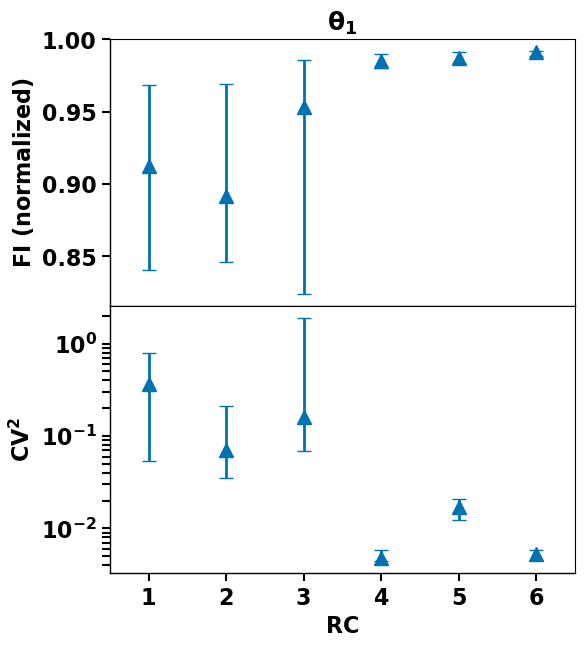

y: [0.3644332  0.071052   0.16184208 0.00475333 0.01687583 0.00523742]
max_vals: [0.78539264 0.21020737 1.8759068  0.00581749 0.02061001 0.0058164 ]
min_vals: [0.05414124 0.0348418  0.06817116 0.00443081 0.01235287 0.00452708]
error: [[3.1029195e-01 3.6210198e-02 9.3670920e-02 3.2251701e-04 4.5229653e-03
  7.1034860e-04]
 [4.2095944e-01 1.3915537e-01 1.7140647e+00 1.0641548e-03 3.7341807e-03
  5.7897763e-04]]
y: [5.3820319e+00 7.6200378e-01 1.3017732e+03 1.1286933e-01 9.3830936e-02
 4.6547845e-02]
max_vals: [4.8087479e+01 1.2746027e+01 7.5140352e+03 3.0464908e-01 1.2120775e-01
 4.8621763e-02]
min_vals: [0.01375163 0.05340897 0.0435187  0.0756807  0.08131536 0.04170678]
error: [[5.3682804e+00 7.0859480e-01 1.3017296e+03 3.7188627e-02 1.2515575e-02
  4.8410632e-03]
 [4.2705448e+01 1.1984023e+01 6.2122617e+03 1.9177976e-01 2.7376816e-02
  2.0739175e-03]]
y: [19.3755      3.3586402   2.7754898   7.4868054  17.441193    0.08803348]
max_vals: [4.3754123e+02 2.2637722e+01 8.2688789e+00 2.2122

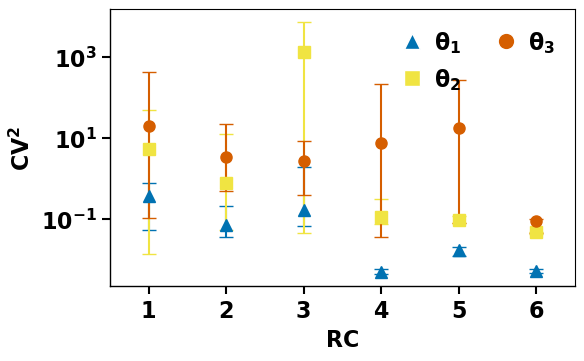

pca_svd_rc_mean_all:
[[[  3.9544084   -1.3946769    2.1911988 ]
  [  3.9786897   -1.3273832    2.184821  ]
  [  3.6185749   -1.1301872    2.1730032 ]
  [  2.3736408    2.6683252    0.29341608]
  [  3.459125     0.6492424   -0.72293127]
  [  3.2698255    1.0496918   -0.7023927 ]
  [  3.3705702   -0.8197185    2.477265  ]
  [  3.0570784   -0.3051815    1.037703  ]
  [  2.2751       1.8179051    0.04723435]
  [  3.990766    -1.208877     2.1373432 ]
  [  3.478722     1.4336483   -2.622142  ]
  [  3.7486846   -1.1958891    2.1146822 ]
  [  3.3497176    1.5602435   -2.254554  ]
  [  3.8113945   -0.6301178    1.970033  ]
  [  3.9968863    1.7256916   -2.6979523 ]
  [  3.116316     1.3256506   -2.424893  ]
  [  1.818112     2.0756938    0.20818138]
  [  4.2902346   -0.7220592    1.9731214 ]
  [  3.9643235   -1.003114     2.4597974 ]
  [  2.506836     3.1496189    0.62568897]
  [  3.7917962   -0.75435024   2.158961  ]
  [  3.2150826    1.4741021   -1.5725282 ]
  [  3.4531896   -0.7423673    0.

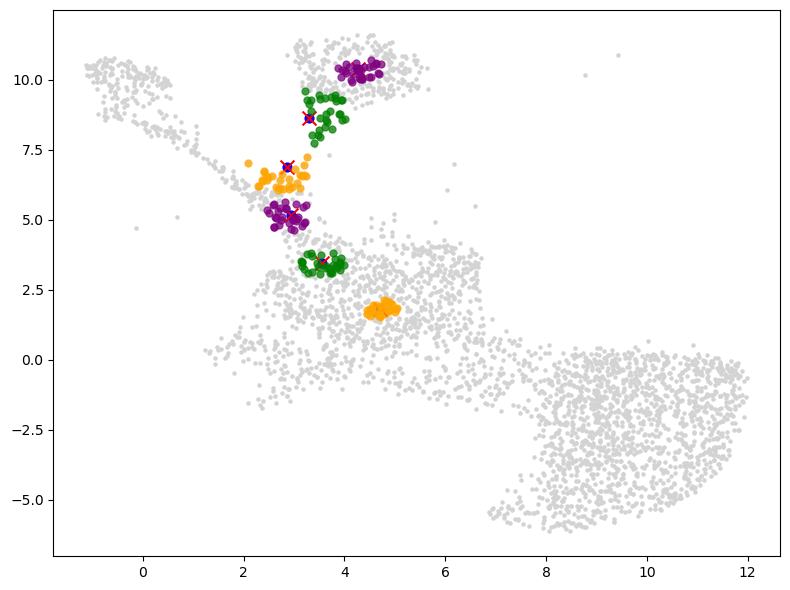

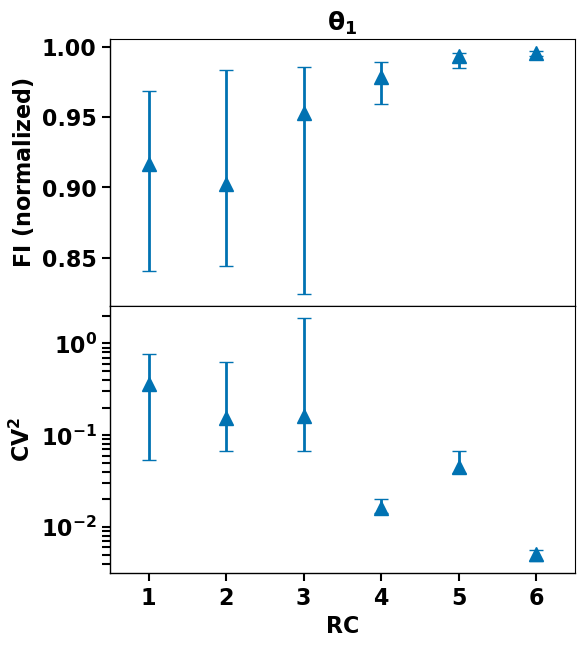

y: [0.3602424  0.153364   0.16323012 0.01624128 0.04560507 0.00502953]
max_vals: [0.77376544 0.62558097 1.8714509  0.02018258 0.06748877 0.0056865 ]
min_vals: [0.05353514 0.06696045 0.06799021 0.01418701 0.03854274 0.00425862]
error: [[3.0670726e-01 8.6403556e-02 9.5239908e-02 2.0542778e-03 7.0623308e-03
  7.7090738e-04]
 [4.1352305e-01 4.7221696e-01 1.7082207e+00 3.9412919e-03 2.1883700e-02
  6.5697124e-04]]
y: [5.0923672e+00 3.6893773e+00 2.1663580e+04 2.0172316e+01 1.4530132e+00
 1.3924006e-01]
max_vals: [5.6818005e+01 7.2159935e+01 2.9668031e+05 2.9723447e+02 2.5736357e+01
 1.3811216e+00]
min_vals: [0.01332808 0.07957306 0.04409714 1.3040522  0.13272525 0.03908462]
error: [[5.0790391e+00 3.6098042e+00 2.1663535e+04 1.8868263e+01 1.3202879e+00
  1.0015544e-01]
 [5.1725639e+01 6.8470558e+01 2.7501672e+05 2.7706216e+02 2.4283344e+01
  1.2418816e+00]]
y: [1.9706095e+01 6.3894409e+01 3.7941802e+00 1.0464693e+00 2.5388270e+04
 7.2980389e-02]
max_vals: [4.6334326e+02 1.1821600e+03 1.42312

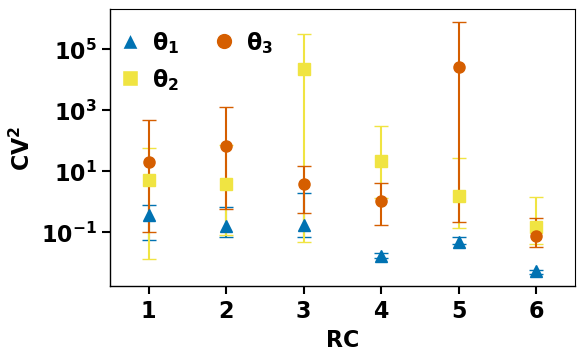

pca_svd_rc_mean_all:
[[[ 3.45190096e+00  6.21532738e-01 -7.35582590e-01]
  [ 3.97713804e+00 -1.38334715e+00  2.25677538e+00]
  [ 3.03585148e+00 -2.79315084e-01  1.06585431e+00]
  [ 2.25259352e+00  1.81784928e+00  4.58568968e-02]
  [ 3.61829829e+00 -1.12007105e+00  2.24651885e+00]
  [ 3.81870246e+00 -6.01675868e-01  2.01911473e+00]
  [ 4.00122118e+00 -1.31577253e+00  2.25015545e+00]
  [ 4.01354790e+00 -1.19476748e+00  2.19790769e+00]
  [ 2.37762690e+00  2.71566606e+00  3.22142690e-01]
  [ 3.25746608e+00  1.03400242e+00 -7.16151118e-01]
  [ 2.48658156e+00  3.13556957e+00  6.07818842e-01]
  [ 3.97797179e+00 -9.90217566e-01  2.53136349e+00]
  [ 3.10431433e+00  1.31176317e+00 -2.49642348e+00]
  [ 3.75223088e+00 -1.18538964e+00  2.18979263e+00]
  [ 3.48871541e+00  1.41792297e+00 -2.69745731e+00]
  [ 3.37300968e+00 -7.99979508e-01  2.55009341e+00]
  [ 3.34670639e+00  1.54911160e+00 -2.32807279e+00]
  [ 1.80051196e+00  2.07646680e+00  2.12009087e-01]
  [ 4.01728296e+00  1.72298837e+00 -2.78950

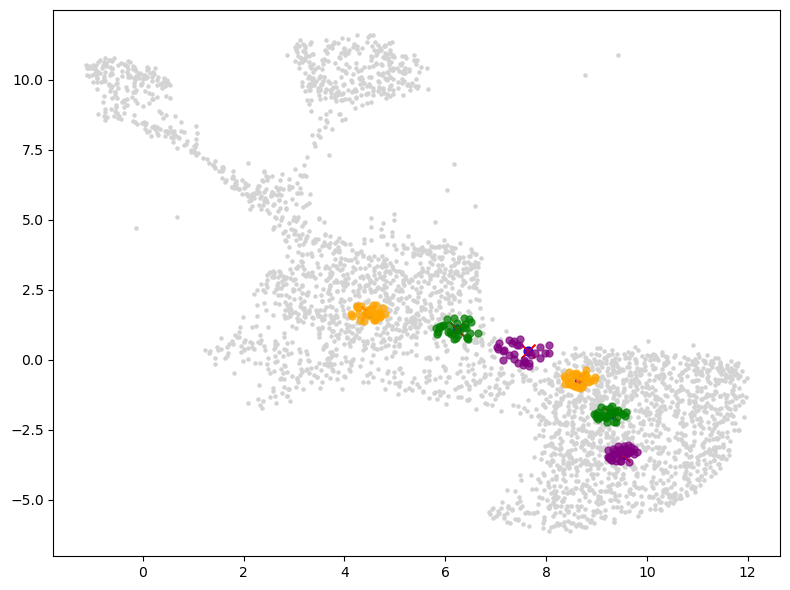

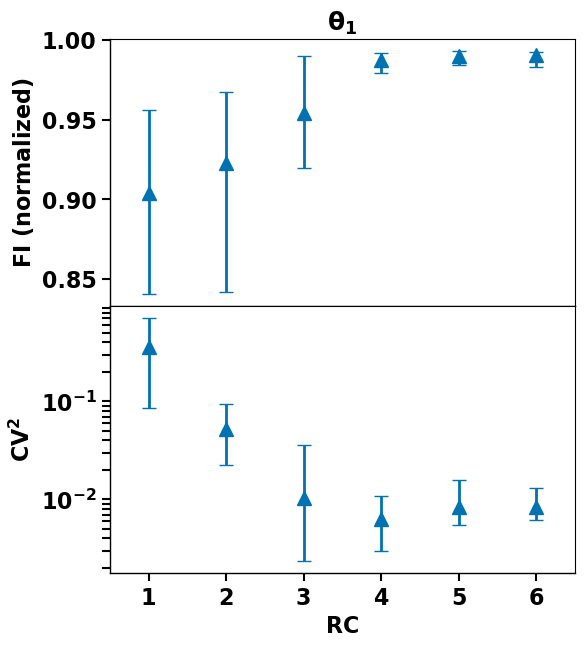

y: [0.357882   0.05248237 0.0103185  0.00628343 0.00840003 0.00834773]
max_vals: [0.70093083 0.09402218 0.03572286 0.01072896 0.01587947 0.01300041]
min_vals: [0.08455504 0.02254223 0.00234816 0.00298193 0.00550064 0.00618486]
error: [[0.27332693 0.02994014 0.00797034 0.0033015  0.0028994  0.00216287]
 [0.34304884 0.04153981 0.02540436 0.00444553 0.00747944 0.00465268]]
y: [1.9576364e+00 2.0973949e-01 1.4895177e+04 1.8889992e-01 1.2369744e-01
 9.8733097e-02]
max_vals: [3.5972710e+01 5.9672672e-01 4.3515578e+05 3.6658785e-01 1.4714588e-01
 1.2323327e-01]
min_vals: [0.015765   0.07175054 1.4617324  0.1016394  0.11367878 0.08690324]
error: [[1.94187140e+00 1.37988955e-01 1.48937148e+04 8.72605219e-02
  1.00186616e-02 1.18298605e-02]
 [3.40150719e+01 3.86987209e-01 4.20260594e+05 1.77687928e-01
  2.34484449e-02 2.45001763e-02]]
y: [9.7438202e+00 1.4389840e+00 8.8022766e+00 2.7072189e+02 1.5320448e+04
 3.0093575e+00]
max_vals: [1.1126593e+02 1.9133989e+01 1.0604161e+02 7.0224619e+03 4.57786

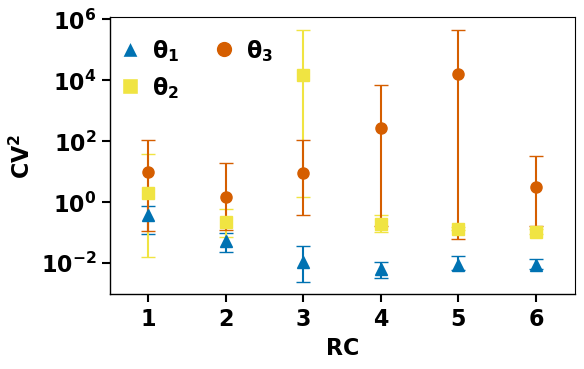

pca_svd_rc_mean_all:
[[[ 3.77421665e+00 -9.95493591e-01  1.44007063e+00]
  [ 3.26861024e+00 -1.10050654e+00  7.29850352e-01]
  [ 3.17649579e+00  1.25504005e+00 -6.28651738e-01]
  [ 3.51516294e+00  1.77413237e+00 -1.77901268e+00]
  [ 2.38000917e+00  2.02008963e+00  6.44051582e-02]
  [ 3.49861479e+00 -1.02403510e+00  1.47947872e+00]
  [ 3.14510059e+00 -1.09609199e+00  1.73314154e+00]
  [ 3.51224065e+00 -1.48229873e+00  1.52300179e+00]
  [ 3.40404177e+00 -1.24945641e+00  1.55404437e+00]
  [ 3.38652778e+00 -1.28427827e+00  1.45913541e+00]
  [ 3.48536515e+00 -1.54290187e+00  1.52606320e+00]
  [ 3.13382983e+00  1.69742024e+00 -1.53998172e+00]
  [ 3.22526503e+00  1.67322969e+00 -9.97704506e-01]
  [ 3.46820116e+00 -1.34929609e+00  1.38819087e+00]
  [ 3.27275372e+00 -1.56736434e+00  1.88632476e+00]
  [ 1.92351711e+00  2.07900453e+00  2.00776041e-01]
  [ 3.17694759e+00 -9.29318726e-01  1.75032759e+00]
  [ 3.27960920e+00 -9.67089117e-01  1.82880902e+00]
  [ 3.20678473e+00  1.44499969e+00 -1.00119

In [4]:
k_nei_list = [10]
K_list = [3]
L_list = [3, 6, 10, 15]
# L_list = [6, 10, 15]
# L_list = [6]

param_combinations = list(itertools.product(k_nei_list, K_list, L_list))

for k_nei, K, L in param_combinations:
    [k_nei, K, L] = [k_nei, K, L]
    print(f"[k_nei, K, L] = [{k_nei}, {K}, {L}]")
    data_name = "zebrafish_dynamo_part"
    figure_path= f"/home/linux/桌面/Is single cell sloppy?/14_画图/figure/cv_2/{data_name}/" + str([k_nei,K,L]) + "/"

    [pca_dim, k_rc, d_pca] = [50, 30, 10]

    clusters_name = "celltype"
    root_cluster = "Ngn3 low EP"
    loc_path_graph = 'upper right'
    basis = "umap"

    branch = [np.array(['Proliferating Progenitor', 'Pigment Progenitor', 'Melanophore']),
            np.array(['Proliferating Progenitor', 'Pigment Progenitor', 'Xanthophore']),
            np.array(['Proliferating Progenitor', 'Schwann Cell Precursor', 'Schwann Cell']) ]

    for t_list in (branch):
        branch_name = t_list[-1]

        adata0 = scv.read(data_path+data_name+'.h5ad', cache=True)
        adata = adata0.copy()
        scv.pp.pca(adata, n_comps=pca_dim)
        scv.pp.neighbors(adata, n_neighbors=k_nei)
        scv.pp.moments(adata, n_pcs=pca_dim, n_neighbors=k_nei)
        scv.tl.velocity(adata)
        print(adata)

        if branch_name == "Schwann Cell":
            nrc = 7
        else:
            nrc = 5

        # average_path = np.load(path_path + f'{data_name}_{branch_name}_P2M_rc_nrc_{nrc}_dpca_{d_pca}.npy') 
        # cell_arr, nearest_cell = find_nearest_indices_voronoi(adata = adata, path0= average_path, rc_distance= "X_pca", n_nei=k_rc, dim_n=10)
        # average_path = np.array(adata[nearest_cell].obsm["X_umap"])[:5]
        # cell_arr = cell_arr[:5] 
        for nrc in [6]:
            average_path = np.load(path_path + f'{data_name}_{branch_name}_P2M_rc_nrc_{nrc}.npy') 
            print("average_path.shape", average_path.shape)
            cell_arr, nearest_cell = find_nearest_indices_voronoi(adata = adata, path0= average_path, n_nei = k_rc, rc_distance= "X_umap")
            
            # fig = sc.pl.embedding(
            #     adata,
            #     # color=[clusters_name, "paga"],
            #     color=[clusters_name],
            #     basis="pca",
            #     color_map=cmap,
            #     return_fig=True
            # )

            X_pca = adata.obsm['X_pca']
            row = np.array([np.ones((k_nei,))*i for i in range(adata.shape[0])]).flatten()
            col = adata.uns['neighbors']['indices'].flatten()
            w_val = np.array([np.linalg.norm(X_pca[int(i),:]-X_pca[int(j),:]) for i,j in zip(row,col)])
            adj_val = np.ones(col.shape)
            A_mat = csr_matrix((adj_val, (row, col)), shape=(adata.shape[0], adata.shape[0]))
            A = A_mat
            W_mat = csr_matrix((w_val, (row, col)), shape=(adata.shape[0], adata.shape[0]))
            dc=np.mean(w_val)
            cell_nei=adata.uns['neighbors']['indices']
            nei_w=[]
            rho_arr=[]
            for ni in adata.uns['neighbors']['indices']:
                dij=np.array([np.linalg.norm(X_pca[int(ni[0]),:]-X_pca[int(i),:]) for i in ni[1:]])
                rho=np.sum(np.exp(-dij**2/dc**2))
                nei_w.append(np.exp(-dij**2/dc**2)/np.sum(np.exp(-dij**2/dc**2)))
                rho_arr.append(rho)
                
            rho_arr=np.array(rho_arr)/np.amax(rho_arr)
            nei_w=np.array(nei_w)
            nei_w=np.hstack((np.ones((nei_w.shape[0],1)),nei_w))/2

            def smooth_func(X_val,cell_nei=cell_nei,nei_w=nei_w):
                X_s=X_val.copy()
                for ci in range(len(X_val)):
                    X_s[ci]=np.dot(X_val[cell_nei[ci,:]],nei_w[ci,:])
                return X_s

            if basis == "umap":
                X_umap = adata.obsm['X_umap']
                X_plt = X_umap[:,0]
                Y_plt = X_umap[:,1]
                X_min = np.min(X_plt)
                X_max = np.max(X_plt)
                Y_min = np.min(Y_plt)
                Y_max = np.max(Y_plt)
                X_len = (X_max-X_min)/5
                Y_len = (Y_max-Y_min)/5
                wid = min(X_len,Y_len)/30
                X_ori = X_min-wid*10
                Y_ori = Y_min-wid*10
            elif basis == "pca":
                X_umap = adata.obsm['X_pca'][:, :2]
                X_plt = X_umap[:,0]
                Y_plt = X_umap[:,1]
                X_min = np.min(X_plt)
                X_max = np.max(X_plt)
                Y_min = np.min(Y_plt)
                Y_max = np.max(Y_plt)
                X_len = (X_max-X_min)/5
                Y_len = (Y_max-Y_min)/5
                wid = min(X_len,Y_len)/30
                X_ori = X_min-wid*10
                Y_ori = Y_min-wid*10

            X = torch.tensor(adata.layers['Ms'], dtype=torch.float32) 
            Encoder_path = "/home/linux/桌面/Is single cell sloppy?/11_PAGA_spectrum/encoder/"
            # for pca in [X_pca, eigengene, hotspot]:

            model_path = Encoder_path + data_name+' '+str([k_nei,K,L])+'/'
            # eigengene = np.load(f"/home/linux/桌面/Is single cell sloppy?/14_画图/Eigengene&hotspot/{data_name}/cell_eigengene_X.npy")
            hotspot = np.load(f"/home/linux/桌面/Is single cell sloppy?/14_画图/Eigengene&hotspot/{data_name}/cell_hs_X.npy")
            model_name = f"{model_path}encoder.pt"
            model = torch.load(f'{model_name}')
            mu, sigma = model(torch.tensor(X))
            mu_learned = mu.detach().numpy()

            sigma_learned = sigma.detach().numpy()
            Fisher_g=np.zeros((X.shape[0],L*2,L*2))
            for i in range(X.shape[0]):
                for j in range(L):
                    Fisher_g[i,j,j]=1/sigma_learned[i,j]**2
                    Fisher_g[i,L+j,L+j]=2/sigma_learned[i,j]**2
            Fisher_g_diag = np.zeros([X.shape[0],L*2])
            for i in range(X.shape[0]):
                Fisher_g_diag[i] = np.diag(Fisher_g[i])
            ## 1_1这一步用了一个神经网络 pca -> Z(mu,sigma), 然后求出这个网络的pZ_pEg。
            for pca in [hotspot]:
                print("pca.shape:", pca.shape)
                reset_seeds(0) # 0
                model = nn.Sequential(
                    nn.Linear(pca.shape[1], 128),
                    nn.ReLU(),
                    nn.Linear(128,64),
                    nn.ReLU(),
                    nn.Linear(64,2*L),
                )
                loss_fn = nn.MSELoss()
                optimizer = SGD(model.parameters(), lr=0.01, weight_decay=0.001)#, momentum=0.2
                x_in=torch.tensor(pca, dtype=torch.float32)
                latent_z = np.hstack((mu_learned,sigma_learned))
                x_out=torch.tensor(latent_z.astype(np.float32))
                for epoch in range(1000): # 200 # NOTE: 500和200的结果不一样。
                # for epoch in range(200): # 200
                    # break
                    optimizer.zero_grad()
                    output = model(x_in)
                    loss = loss_fn(output,x_out) 
                    loss.backward()
                    optimizer.step()
                pZ_ppca = p_out_p_in(pca, model, dim_out = 2 * L)

                ### 链式法则（已知FI_Z），求出FI_pca。
                FI_pca = np.einsum("ijk,ij,ijh->ikh",pZ_ppca, Fisher_g_diag, pZ_ppca)
                print("FI_pca.shape:", FI_pca.shape)
                # FI_Eg_diag = FI_Eg[:, range(eigengene.shape[1]), range(eigengene.shape[1])]
                # U_FI_Eg[i]的列向量是特征向量。Ax = /lamba x (从这可以看出x是列向量)
                # 不过U_FI_Eg[i]的行向量和列向量的模长都是1.而且行和行彼此正交。列和列彼此正交。这是因为UU_T = I. U是正交矩阵。
                U_FI_Eg, S_FI_Eg, Vt_FI_Eg = np.linalg.svd(FI_pca, full_matrices=False)
                print("svd后(U_FI_Eg, S_FI_Eg, Vt_FI_Eg)：",U_FI_Eg.shape, S_FI_Eg.shape, Vt_FI_Eg.shape)

                print("S_FI_Eg:", S_FI_Eg)

                # rc_path(adata, mu_learned, sigma_learned, average_path, basis, k_nei, data_name)
                cell_arr_plot(average_path, cell_arr, X_umap)
                # rc_path_celltype(adata, average_path, basis, data_name, save = save, figure_path = figure_path, branch_name  = branch_name)
                    
                dim = 3
                # U_FI_Eg和pca的各列都是正交的才可以这么算。cell_i_的pca坐标（向量）点积u1得到的就是u1的坐标，这其实就是在u1上做投影。
                # NOTE:这可能是为什么eigengene和hotspot不行的原因，eigengene的各坐标系间不是正交的。
                pca_svd_rc_variance_all, pca_svd_rc_mean_all= compute_variances(U_FI_Eg, pca, cell_arr, k_rc= k_rc, L = L, simple=dim/2, cv= True)
                pca_svd_rc_variance_average = np.array([np.mean(arr, axis=0) for arr in pca_svd_rc_variance_all])

                # print("pca_svd_rc_variance_all.shape",pca_svd_rc_variance_all[0].shape)
                # plot_all_variances_odd(pca_svd_rc_variance_all, share_y = False)
                FI_VAR_double_grid(S_FI_Eg, pca_svd_rc_variance_all, pca, 0.5, cell_arr, norm=True, simple= True,
                                save = save, figure_path = figure_path, branch_name  = branch_name)

                exclude_indices = []
                all_indices = list(range(len(pca_svd_rc_variance_all)))
                keep_indices = [i for i in all_indices if i not in exclude_indices]
                new_array = np.array(pca_svd_rc_variance_all)[keep_indices]

                variance_along_rc(cell_arr, new_array, dim = dim, save = save, figure_path = figure_path, branch_name  = branch_name)

                print("pca_svd_rc_mean_all:")
                print(np.array(pca_svd_rc_mean_all))